# Exploratory Data Analysis(EDA)
**House Demand Forecasting**

Hauptanalyse: September 2017 bis August 2025 (96 Monate); Saison-Heatmaps: vollständige Jahre 2018–2024.
Das Testjahr September 2025 bis August 2026 wird nicht ausgewertet.



## 1 Darstellung


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

project_dir = Path(r"C:\Users\matavela\Desktop\House_Demand_Forecasting")
data_dir = project_dir / "daten"
output_dir = project_dir / "ergebnisse" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

blue = "#215B89"
dark_blue = "#08306B"
light_blue = "#BDD7E7"
red = "#C42B32"
month_labels = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
                "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
target_labels = {
    "dom": "Vermarktungsdauer (DOM)",
    "pending": "Angebote mit vereinbartem Kauf (Pending)",
}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white",
})

## 2 Monatsdaten und Analysefenster
Zinsen werden aus Wochenwerten monatlich gemittelt; für die Robustheitsprüfung wird zusätzlich der Monatsmedian berechnet.
Die übrigen Reihen liegen bereits monatlich vor. Fehlwerte werden nicht ersetzt.
Der längere Abschnitt ab November 2016 dient ausschließlich dem Vergleich mit dem Pending-Anfangssegment.

In [17]:
def load_series(file_name, value_column):
    data_frame = pd.read_csv(
        data_dir / file_name, na_values=[".", "", "NA"]
    )
    dates = pd.to_datetime(data_frame["observation_date"], errors="raise")
    values = pd.to_numeric(data_frame[value_column], errors="raise")
    if dates.isna().any() or dates.duplicated().any():
        raise ValueError(f"Fehlende oder doppelte Datumsangaben: {file_name}")
    return pd.Series(values.to_numpy(), index=dates).sort_index()

series_config = {
    "dom": ("MEDDAYONMAR53033.csv", "MEDDAYONMAR53033"),
    "pending": ("PENLISCOU53033.csv", "PENLISCOU53033"),
    "active": ("ACTLISCOU53033.csv", "ACTLISCOU53033"),
    "building_permits": (
        "Building_Permits_Seattle_2016_2026.csv", "authorized_units_total"
    ),
}
monthly_series = {
    name: load_series(*config) for name, config in series_config.items()
}
weekly_mortgage = load_series("MORTGAGE30US.csv", "MORTGAGE30US")
monthly_series["mortgage_rate"] = weekly_mortgage.resample("MS").mean()
monthly_data = pd.concat(monthly_series, axis=1, sort=True).sort_index()
development_data = monthly_data.loc["2017-09-01":"2025-08-01"].copy()
extended_data = monthly_data.loc["2016-11-01":"2025-08-01"].copy()

expected_months = pd.date_range("2017-09-01", "2025-08-01", freq="MS")
if not development_data.index.equals(expected_months):
    raise ValueError("Die monatliche Zeitachse ist unvollständig.")
if development_data.isna().any().any():
    raise ValueError("Fehlende Werte im Hauptanalysezeitraum prüfen.")

display(pd.DataFrame([
    ["Hauptanalyse", "09/2017–08/2025", len(development_data)],
    ["Mit Pending-Anfangssegment", "11/2016–08/2025", len(extended_data)],
    ["Saison-Heatmaps", "01/2018–12/2024", 84],
], columns=["Auswertung", "Zeitraum", "Monate"]))

,Auswertung,Zeitraum,Monate
0,Hauptanalyse,09/2017–08/2025,96
1,Mit Pending-Anfangssegment,11/2016–08/2025,106
2,Saison-Heatmaps,01/2018–12/2024,84


## 3 H1 und H2
Pearson-Korrelation r beschreibt den linearen Zusammenhang zwischen zwei Reihen.
Für H1 werden DOM und Pending vor und ab Januar 2022 verglichen.
Für H2 werden Zinsen mit Zielwerten zwei bis vier Monate später verglichen.
Vorjahresveränderung bedeutet Monatswert minus Wert zwölf Monate zuvor; bei Zinsen ist die Einheit Prozentpunkte.
Verschiebungen erfolgen auf der vollständigen Monatsachse, erst danach wird der Auswertungszeitraum gewählt. Keine kausalen Tests.

In [4]:
def correlation_pair(data_frame, predictor, target, lag=0, yearly_change=False):
    transformed_data = data_frame.diff(12) if yearly_change else data_frame
    return pd.concat([
        transformed_data[predictor].shift(lag).rename("predictor"),
        transformed_data[target].rename("target"),
    ], axis=1).dropna()

hypothesis_rows = []
periods = {
    "Gesamt": ("2017-09", "2025-08"),
    "Vor 2022": ("2017-09", "2021-12"),
    "Ab 2022": ("2022-01", "2025-08"),
}
for period_name, (start_date, end_date) in periods.items():
    pairs = correlation_pair(development_data, "dom", "pending")
    pairs = pairs.loc[start_date:end_date]
    hypothesis_rows.append({
        "Hypothese": "H1", "Vergleich": "DOM / Pending",
        "Zeitraum": period_name, "Darstellung": "Monatswerte",
        "Vorlauf (Monate)": 0, "Monatspaare": len(pairs),
        "Pearson r": pairs["predictor"].corr(pairs["target"]),
    })

for target in ["dom", "pending"]:
    for yearly_change in [False, True]:
        for lag in [2, 3, 4]:
            pairs = correlation_pair(
                development_data, "mortgage_rate", target, lag, yearly_change
            )
            hypothesis_rows.append({
                "Hypothese": "H2",
                "Vergleich": f"Zinsen / {target_labels[target]}",
                "Zeitraum": "Gesamt",
                "Darstellung": "Vorjahresdifferenzen" if yearly_change else "Monatswerte",
                "Vorlauf (Monate)": lag, "Monatspaare": len(pairs),
                "Pearson r": pairs["predictor"].corr(pairs["target"]),
            })

hypothesis_results = pd.DataFrame(hypothesis_rows)
display(hypothesis_results.round(3))

,Hypothese,Vergleich,Zeitraum,Darstellung,Vorlauf (Monate),Monatspaare,Pearson r
0,H1,DOM / Pending,Gesamt,Monatswerte,0,96,-0.533
1,H1,DOM / Pending,Vor 2022,Monatswerte,0,52,-0.504
2,H1,DOM / Pending,Ab 2022,Monatswerte,0,44,-0.679
3,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Monatswerte,2,94,0.248
4,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Monatswerte,3,93,0.249
5,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Monatswerte,4,92,0.244
6,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Vorjahresdifferenzen,2,82,0.429
7,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Vorjahresdifferenzen,3,81,0.489
8,H2,Zinsen / Vermarktungsdauer (DOM),Gesamt,Vorjahresdifferenzen,4,80,0.519
9,H2,Zinsen / Angebote mit vereinbartem Kauf (Pending),Gesamt,Monatswerte,2,94,-0.506


## 4 Verteilungen nach Kalendermonat​
Je Kalendermonat werden acht Werte verglichen. Die rote Linie zeigt den Median, die Box reicht vom 25-%- bis zum 75-%-Quantil.
Einzelpunkte zeigen die Monatsbeobachtungen.

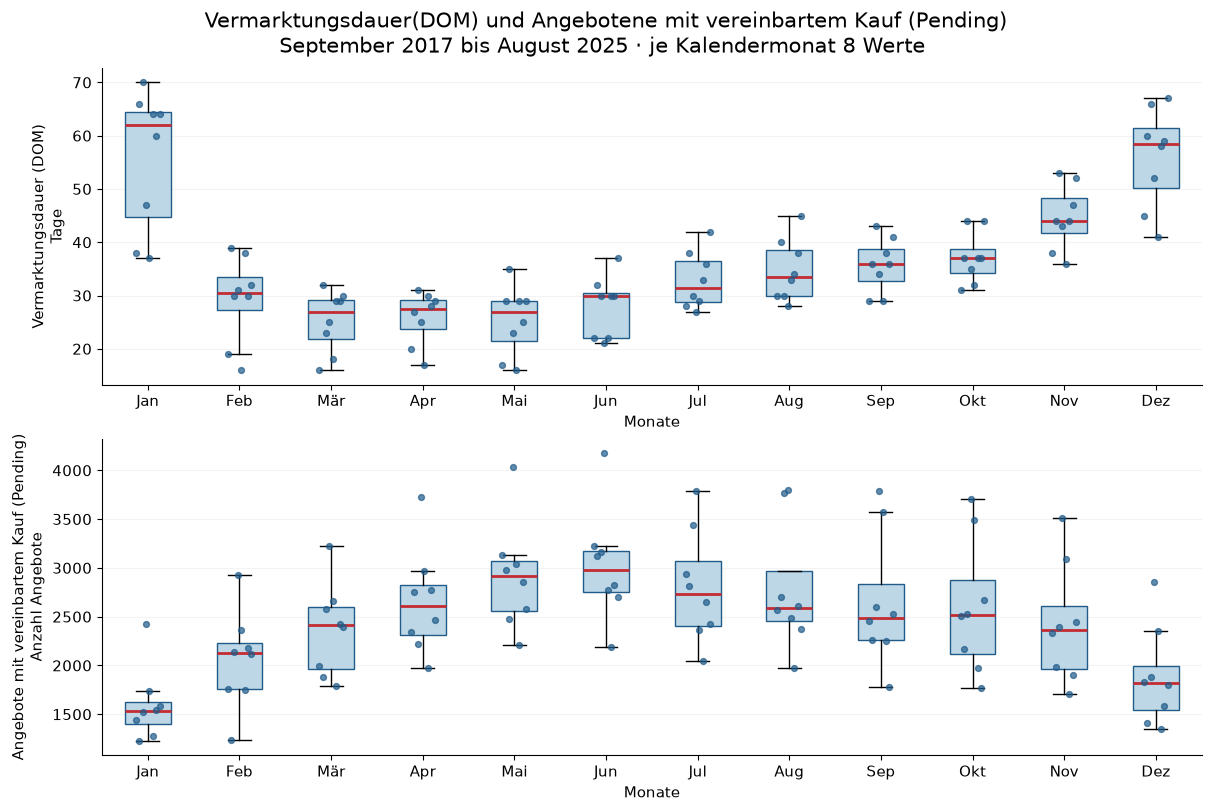

,Vermarktungsdauer (DOM),Angebote mit vereinbartem Kauf (Pending)
Jan,62.0,1535.0
Feb,30.5,2125.5
Mär,27.0,2411.5
Apr,27.5,2612.5
Mai,27.0,2914.5
Jun,30.0,2973.5
Jul,31.5,2734.5
Aug,33.5,2592.0
Sep,36.0,2488.0
Okt,37.0,2516.0


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")

for axis, target, unit in zip(axes, ["dom", "pending"], ["Tage", "Anzahl Angebote"]):
    monthly_values = [
        development_data.loc[development_data.index.month == month, target].to_numpy()
        for month in range(1, 13)
    ]
    boxplot = axis.boxplot(
        monthly_values, patch_artist=True,
        medianprops={"color": red, "linewidth": 2},
        showfliers=False,
    )
    for box in boxplot["boxes"]:
        box.set_facecolor(light_blue)
        box.set_edgecolor(blue)
    for month, values in enumerate(monthly_values, 1):
        axis.scatter(
            month + np.linspace(-0.13, 0.13, len(values)), values,
            s=18, color=blue, alpha=0.7, zorder=3,
        )
    axis.set_xticks(range(1, 13), month_labels)
    axis.set_xlabel("Monate")
    axis.set_ylabel(f"{target_labels[target]}\n{unit}")
    axis.grid(axis="y", alpha=0.15)

fig.suptitle("Vermarktungsdauer(DOM) und Angebotene mit vereinbartem Kauf (Pending)\nSeptember 2017 bis August 2025 · je Kalendermonat 8 Werte ", fontsize=15)

fig.savefig(output_dir / "01_monatsboxplots.png", dpi=200)
plt.show()
plt.close(fig)

monthly_medians = (
    development_data[["dom", "pending"]]
    .groupby(development_data.index.month).median()
    .rename(columns=target_labels)
)
monthly_medians.index = month_labels
display(monthly_medians.round(1))

## 5 Wiederholung der Saisonmuster​
Für jedes vollständige Jahr wird (Monatswert / eigener Jahresdurchschnitt − 1) × 100 berechnet.
Das −1 zieht das Ausgangsniveau ab; 0 % entspricht dem Jahresdurchschnitt.
Die Farben zeigen Abweichungen, keine Korrelationen. Jahresmaxima werden aus ungerundeten Werten ermittelt.

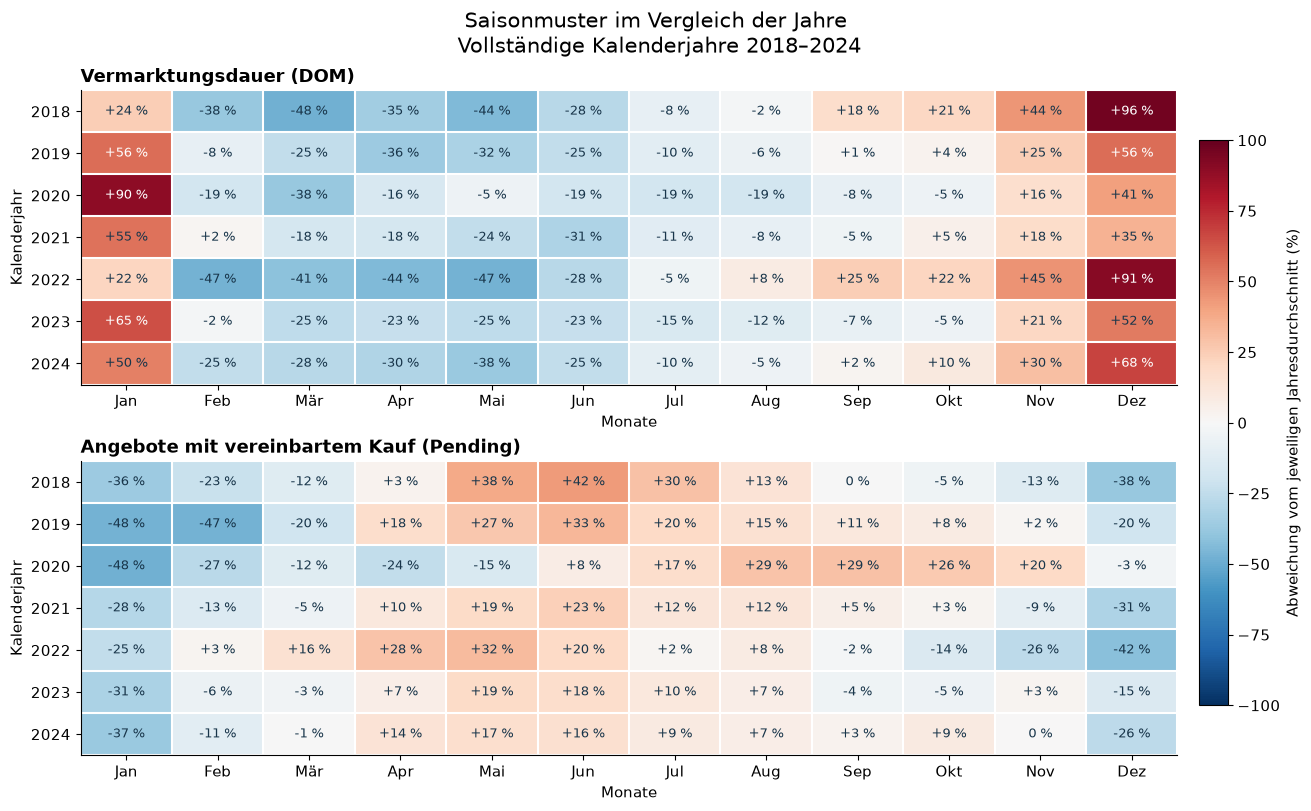

,Variable,Jahr,Monat des Maximums,Dezemberabweichung (%)
0,Vermarktungsdauer (DOM),2018,Dez,96.2
1,Vermarktungsdauer (DOM),2019,"Jan, Dez",55.6
2,Vermarktungsdauer (DOM),2020,Jan,40.9
3,Vermarktungsdauer (DOM),2021,Jan,34.8
4,Vermarktungsdauer (DOM),2022,Dez,90.7
5,Vermarktungsdauer (DOM),2023,Jan,51.9
6,Vermarktungsdauer (DOM),2024,Dez,67.5
7,Angebote mit vereinbartem Kauf (Pending),2018,Jun,-38.0
8,Angebote mit vereinbartem Kauf (Pending),2019,Jun,-19.7
9,Angebote mit vereinbartem Kauf (Pending),2020,Sep,-2.6


In [7]:
complete_years = development_data.loc["2018-01":"2024-12"]
seasonal_deviations = {}
seasonal_rows = []
fig, axes = plt.subplots(2, 1, figsize=(13, 8), layout="constrained")

for axis, target in zip(axes, ["dom", "pending"]):
    year_month_values = (
        complete_years.assign(
            year=complete_years.index.year, month=complete_years.index.month
        ).pivot(index="year", columns="month", values=target)
    )
    deviations = (
        year_month_values.div(year_month_values.mean(axis=1), axis=0) - 1
    ) * 100
    seasonal_deviations[target] = deviations
    heatmap = axis.imshow(
        deviations, cmap="RdBu_r",
        norm=TwoSlopeNorm(vmin=-100, vcenter=0, vmax=100), aspect="auto",
    )
    axis.set_xticks(range(12), month_labels)
    axis.set_yticks(range(len(deviations)), deviations.index)
    axis.set_xlabel("Monate")
    axis.set_ylabel("Kalenderjahr")
    axis.set_title(target_labels[target], loc="left", fontweight="bold")
    for row in range(len(deviations)):
        for column in range(12):
            value = deviations.iloc[row, column]
            axis.text(
                column, row, "0 %" if abs(value) < 0.5 else f"{value:+.0f} %",
                ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 55 else "#18354A",
            )
    axis.set_xticks(np.arange(-0.5, 12, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, len(deviations), 1), minor=True)
    axis.grid(which="minor", color="white", linewidth=1.5)
    axis.tick_params(which="minor", bottom=False, left=False)
    for year, values in year_month_values.iterrows():
        maximum_months = values.index[values.eq(values.max())]
        seasonal_rows.append({
            "Variable": target_labels[target], "Jahr": year,
            "Monat des Maximums": ", ".join(month_labels[month - 1] for month in maximum_months),
            "Dezemberabweichung (%)": deviations.loc[year, 12],
        })

fig.colorbar(
    heatmap, ax=axes, shrink=0.85, pad=0.02,
    label="Abweichung vom jeweiligen Jahresdurchschnitt (%)",
)
fig.suptitle("Saisonmuster im Vergleich der Jahre\n Vollständige Kalenderjahre 2018–2024", fontsize=15)
fig.savefig(output_dir / "02_saison_heatmaps.png", dpi=200)
plt.show()
plt.close(fig)
seasonal_summary = pd.DataFrame(seasonal_rows)
display(seasonal_summary.round(1))

## 6 Angebot und spätere Vermarktungsdauer​
Berechnet wird corr(Active im Monat t, DOM im Monat t + k) für k = 0 bis 12.
Die beiden Grafiken verwenden Monatswerte und absolute Vorjahresdifferenzen.
Rot markiert das Maximum, keine statistische Signifikanz. Die Anzahl der Monatspaare nimmt mit dem Abstand ab.

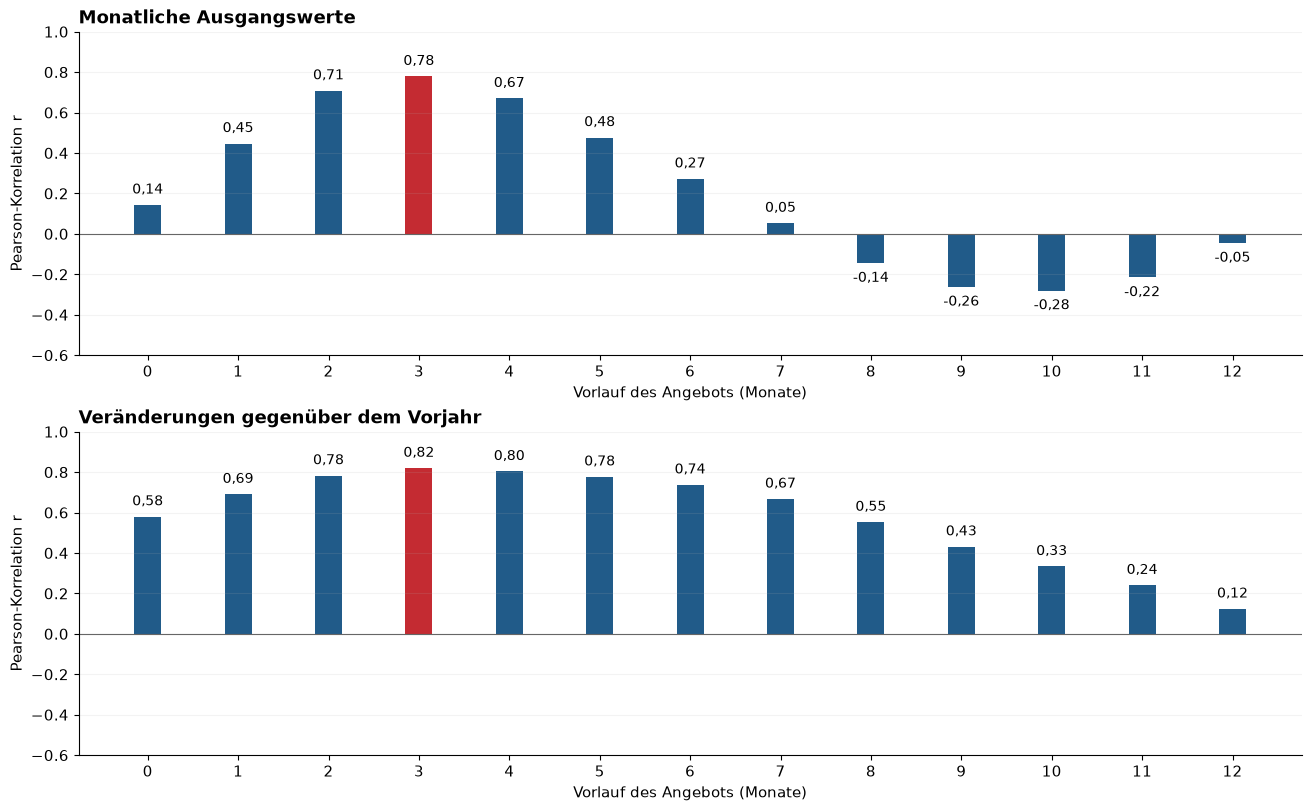

,Darstellung,Vorlauf (Monate),Pearson r,Monatspaare
3,Monatliche Ausgangswerte,3,0.779,93
16,Veränderungen gegenüber dem Vorjahr,3,0.819,81


In [16]:
correlation_rows = []
fig, axes = plt.subplots(2, 1, figsize=(13, 8), layout="constrained")

for axis, yearly_change, title in zip(
    axes, [False, True], ["Monatliche Ausgangswerte", "Veränderungen gegenüber dem Vorjahr"]
):
    correlation_values = []
    pair_counts = []
    for lag in range(13):
        pairs = correlation_pair(
            development_data, "active", "dom", lag, yearly_change
        )
        correlation = pairs["predictor"].corr(pairs["target"])
        correlation_values.append(correlation)
        pair_counts.append(len(pairs))
        correlation_rows.append({
            "Darstellung": title, "Vorlauf (Monate)": lag,
            "Pearson r": correlation, "Monatspaare": len(pairs),
        })
    maximum_lag = int(np.nanargmax(correlation_values))
    axis.bar(
        range(13), correlation_values, width=0.3,
        color=[red if lag == maximum_lag else blue for lag in range(13)],
    )
    for lag, value in enumerate(correlation_values):
        axis.text(
            lag, value + (0.04 if value >= 0 else -0.04),
            f"{value:.2f}".replace(".", ","),
            ha="center", va="bottom" if value >= 0 else "top", fontsize=10,
        )
    axis.set_title(title, loc="left", fontweight="bold")
    axis.set_xticks(range(13))
    axis.set_ylim(-0.6, 1)
    axis.set_xlabel("Vorlauf des Angebots (Monate)")
    axis.set_ylabel("Pearson-Korrelation r")
    axis.axhline(0, color="#666666", linewidth=0.8)
    axis.grid(axis="y", alpha=0.15)

fig.savefig(output_dir / "03_kreuzkorrelation.png", dpi=200)
plt.show()
plt.close(fig)
cross_correlations = pd.DataFrame(correlation_rows)
display(cross_correlations.loc[cross_correlations["Vorlauf (Monate)"].eq(3)].round(3))

## 7 Robustheit der Befunde​
Vier Varianten: Hauptanalyse, zusätzliches Pending-Anfangssegment, Ausschluss von 2020–2021 und Monatsmedian der Zinsen statt Mittelwert.


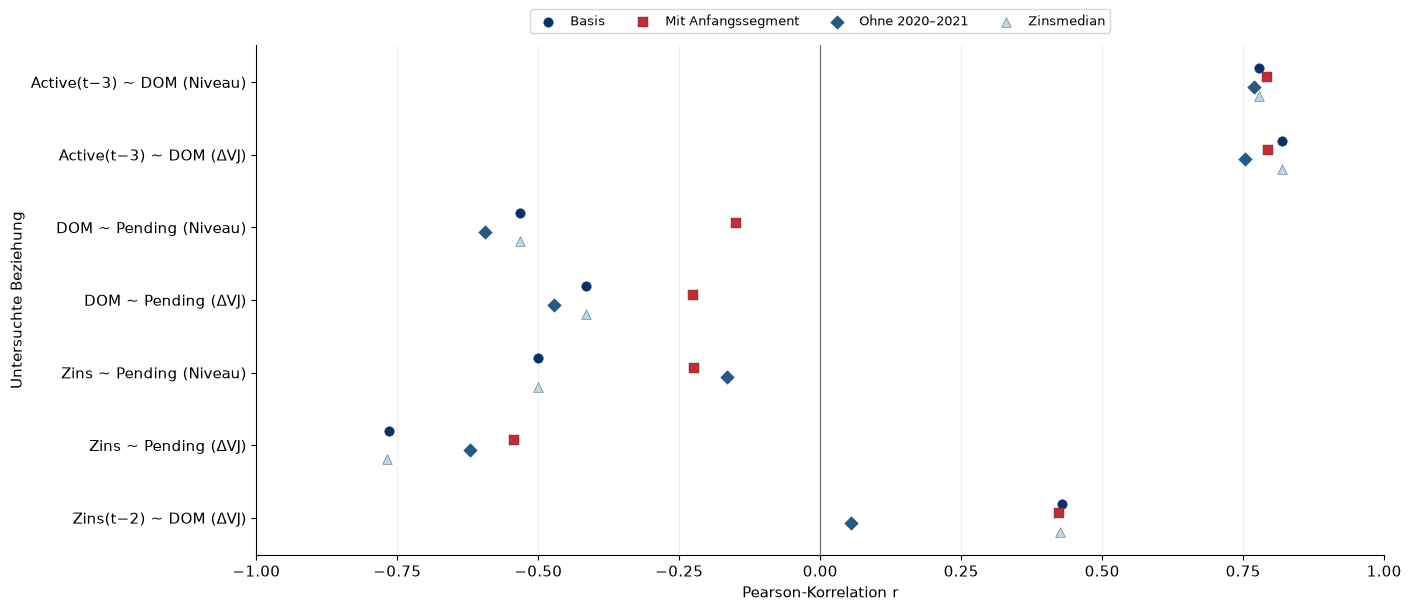

,Variante,Beziehung,Pearson r,Monatspaare
0,Basis,Active(t−3) ~ DOM (Niveau),0.779,93
1,Basis,Active(t−3) ~ DOM (ΔVJ),0.819,81
2,Basis,DOM ~ Pending (Niveau),-0.533,96
3,Basis,DOM ~ Pending (ΔVJ),-0.415,84
4,Basis,Zins ~ Pending (Niveau),-0.500,96
5,Basis,Zins ~ Pending (ΔVJ),-0.765,84
6,Basis,Zins(t−2) ~ DOM (ΔVJ),0.429,82
7,Mit Anfangssegment,Active(t−3) ~ DOM (Niveau),0.792,103
8,Mit Anfangssegment,Active(t−3) ~ DOM (ΔVJ),0.794,91
9,Mit Anfangssegment,DOM ~ Pending (Niveau),-0.150,105


In [13]:
median_data = development_data.copy()
median_data["mortgage_rate"] = (
    weekly_mortgage.resample("MS").median().reindex(development_data.index)
)
excluded_data = development_data.copy()
excluded_data.loc[excluded_data.index.year.isin([2020, 2021]), :] = np.nan

variants = {
    "Basis": development_data,
    "Mit Anfangssegment": extended_data,
    "Ohne 2020–2021": excluded_data,
    "Zinsmedian": median_data,
}
relationships = [
    ("Active(t−3) ~ DOM (Niveau)", "active", "dom", 3, False),
    ("Active(t−3) ~ DOM (ΔVJ)", "active", "dom", 3, True),
    ("DOM ~ Pending (Niveau)", "dom", "pending", 0, False),
    ("DOM ~ Pending (ΔVJ)", "dom", "pending", 0, True),
    ("Zins ~ Pending (Niveau)", "mortgage_rate", "pending", 0, False),
    ("Zins ~ Pending (ΔVJ)", "mortgage_rate", "pending", 0, True),
    ("Zins(t−2) ~ DOM (ΔVJ)", "mortgage_rate", "dom", 2, True),
]
robustness_rows = []
for variant_name, data_frame in variants.items():
    for label, predictor, target, lag, yearly_change in relationships:
        pairs = correlation_pair(data_frame, predictor, target, lag, yearly_change)
        robustness_rows.append({
            "Variante": variant_name, "Beziehung": label,
            "Pearson r": pairs["predictor"].corr(pairs["target"]),
            "Monatspaare": len(pairs),
        })
robustness_results = pd.DataFrame(robustness_rows)

fig, axis = plt.subplots(figsize=(14, 6), layout="constrained")
variant_colors = [dark_blue, red, blue, light_blue]
variant_markers = ["o", "s", "D", "^"]
for offset, (variant_name, color, marker) in enumerate(
    zip(variants, variant_colors, variant_markers)
):
    variant_results = (
        robustness_results.loc[robustness_results["Variante"].eq(variant_name)]
        .set_index("Beziehung").reindex([item[0] for item in relationships])
    )
    axis.scatter(
        variant_results["Pearson r"],
        np.arange(len(relationships)) + (offset - 1.5) * 0.13,
        color=color, marker=marker, s=48, label=variant_name,
        edgecolors="#334155", linewidths=0.3, zorder=3,
    )
axis.set_yticks(range(len(relationships)), [item[0] for item in relationships])
axis.invert_yaxis()
axis.set_xlim(-1, 1)
axis.set_xlabel("Pearson-Korrelation r")
axis.set_ylabel("Untersuchte Beziehung")
axis.axvline(0, color="#666666", linewidth=0.8)
axis.grid(axis="x", alpha=0.2)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=4, fontsize=9)
fig.savefig(output_dir / "04_robustheit.png", dpi=200)
plt.show()
plt.close(fig)
display(robustness_results.round(3))